## C4 · Principles of good plots

Six principles for plots that answer a question clearly and honestly, each shown as a plot that works and a better one, and a check to run on a plot before using it.

In [952]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Plot defaults: wide 16:9 figures, sharp ("retina") output and slightly smaller text
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({
    "figure.figsize": (6.4, 3.6),
    "figure.dpi": 100,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

# Same data as sns.load_dataset('penguins'), saved locally so it works offline
df_penguins = pd.read_csv("data/penguins.csv")

### The principles

#### Six principles of good plots

**C4.01**

***(non-examinable)***

A good plot answers one question, can be read without the code, and gives an honest picture of the data. These six principles are a short list to think about while plotting and before a figure goes into a report.

1. **Choose the plot for the question:** spread, comparison of groups, or relationship.
2. **Label the axes with names and units,** and give the plot a title that says what it shows.
3. **Start bar charts at zero,** because a bar is read by its length.
4. **Show the data, not only the averages,** so the spread and overlap can be seen.
5. **Use colours that every reader can tell apart,** and a second cue such as marker shape.
6. **Give each figure one message,** and leave out what does not support it.

One plot that follows all six:

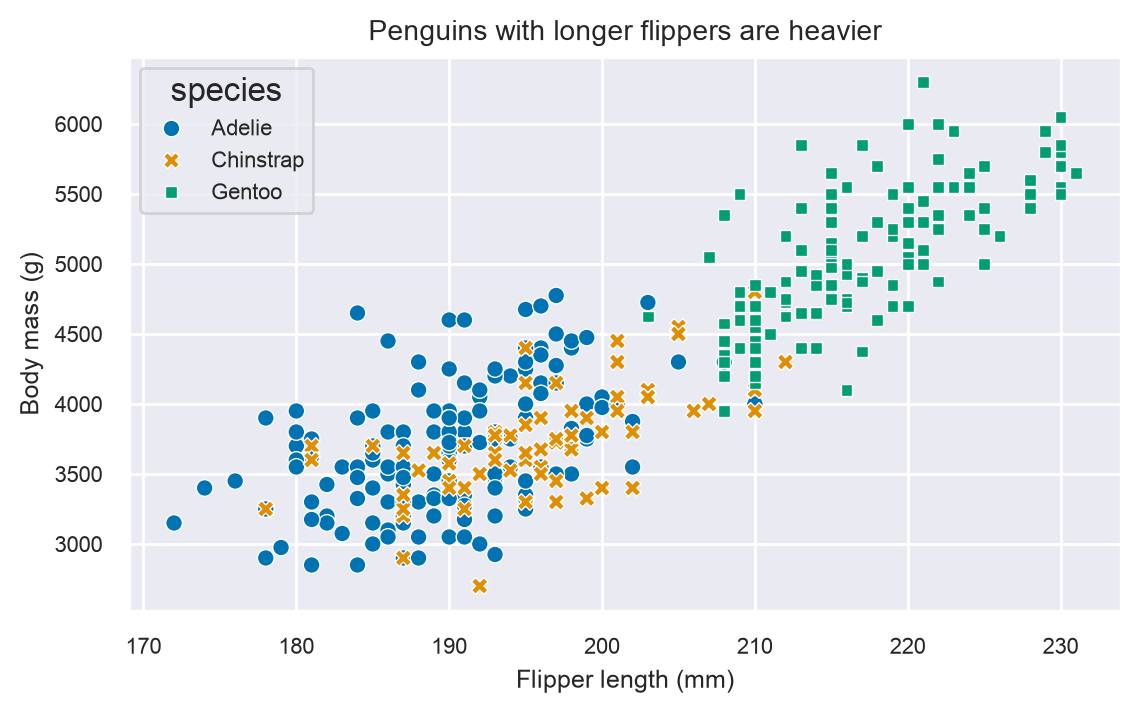

In [953]:
fig, ax = plt.subplots()
sns.scatterplot(data=df_penguins, x="flipper_length_mm", y="body_mass_g",
                hue="species", style="species", palette="colorblind", ax=ax)
ax.set(title="Penguins with longer flippers are heavier",
       xlabel="Flipper length (mm)", ylabel="Body mass (g)");

*See also:* Choosing a plot for the question (C4) · Checking a plot before using it (C4) · Adding a title and axis labels (C1)

### Choosing and labelling

#### Choosing a plot for the question

**C4.02**

`spread → histplot   groups → boxplot   relationship → scatterplot`

***(non-examinable)***

The question decides the plot: a histogram shows how one variable is spread, a box plot compares a variable across groups, and a scatter plot shows how two variables are related.

| Question | Plot |
|---|---|
| How is one variable spread? | histogram, box plot |
| How do groups differ? | box plot, strip plot, violin plot |
| How are two variables related? | scatter plot (line plot when x is time) |
| How many in each category? | bar chart of counts |

The same data, three questions:

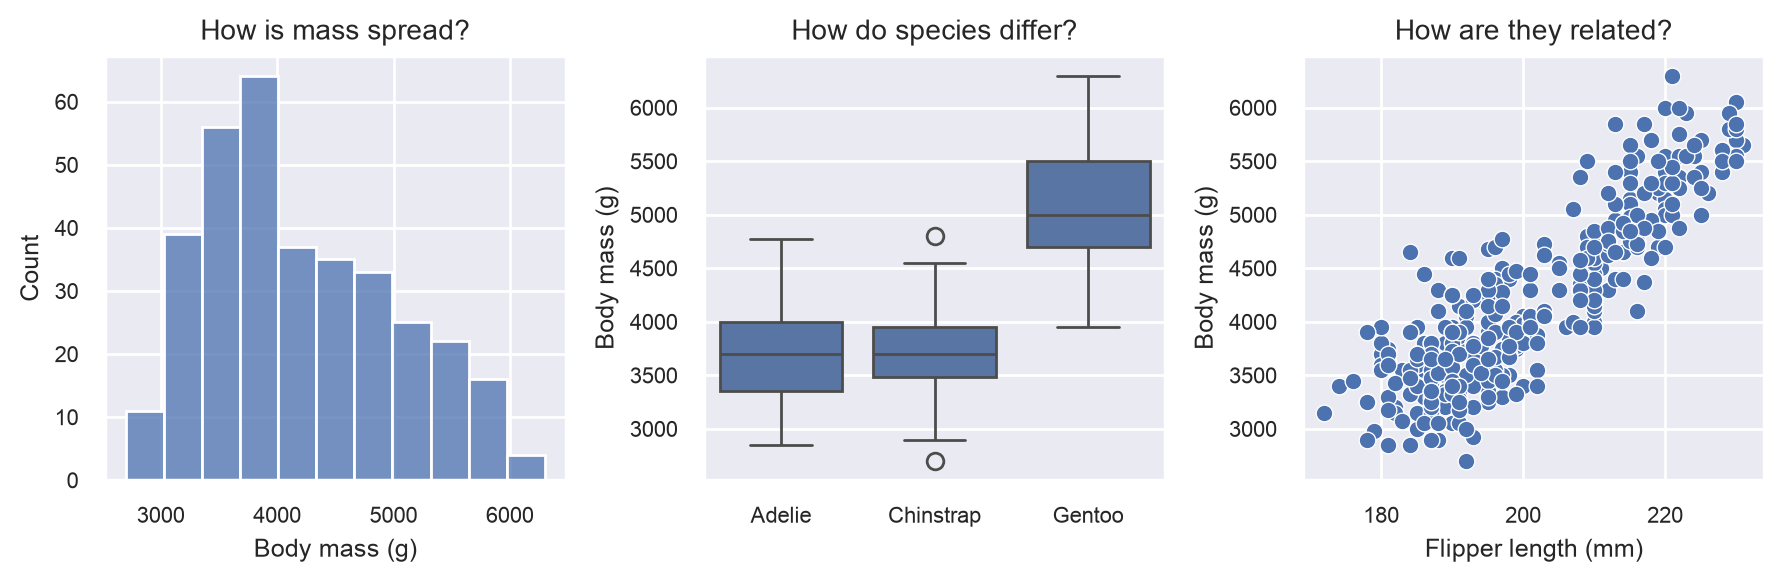

In [954]:
fig, axs = plt.subplots(1, 3, figsize=(9, 3))
sns.histplot(data=df_penguins, x="body_mass_g", ax=axs[0])
axs[0].set(title="How is mass spread?", xlabel="Body mass (g)")
sns.boxplot(data=df_penguins, x="species", y="body_mass_g", ax=axs[1])
axs[1].set(title="How do species differ?", xlabel="", ylabel="Body mass (g)")
sns.scatterplot(data=df_penguins, x="flipper_length_mm", y="body_mass_g", ax=axs[2])
axs[2].set(title="How are they related?",
           xlabel="Flipper length (mm)", ylabel="Body mass (g)")
fig.tight_layout();

*See also:* Drawing a histogram with `histplot` (C3) · Drawing a box plot with `boxplot` (C3) · Drawing a scatter plot with `scatterplot` (C3) · Drawing a bar chart (C2) · Drawing a simple line plot (C1)

#### Labelling axes with names and units

**C4.03**

`ax.set(title="…", xlabel="Name (unit)", ylabel="Name (unit)")`

***(non-examinable)***

Plotting functions label the axes with the column names, which are written for code (`body_mass_g`); a reader needs words and units, and a title that says what the plot shows.

The first plot keeps the column names as labels and has no title:

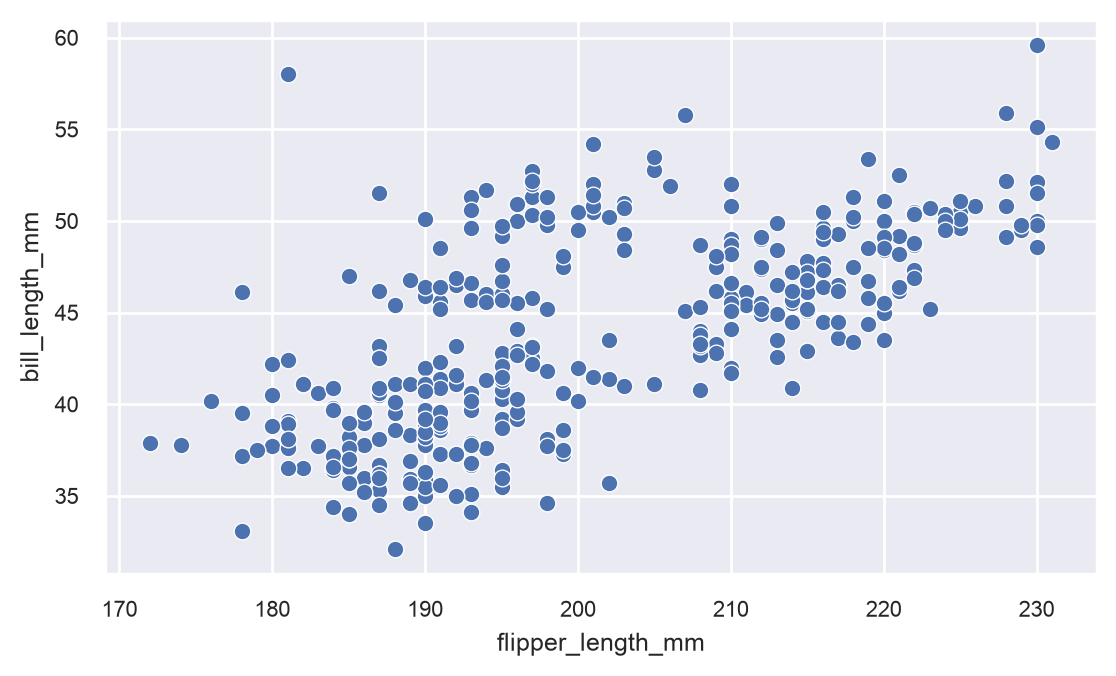

In [955]:
sns.scatterplot(data=df_penguins, x="flipper_length_mm", y="bill_length_mm");

The second says what each axis measures, in which unit:

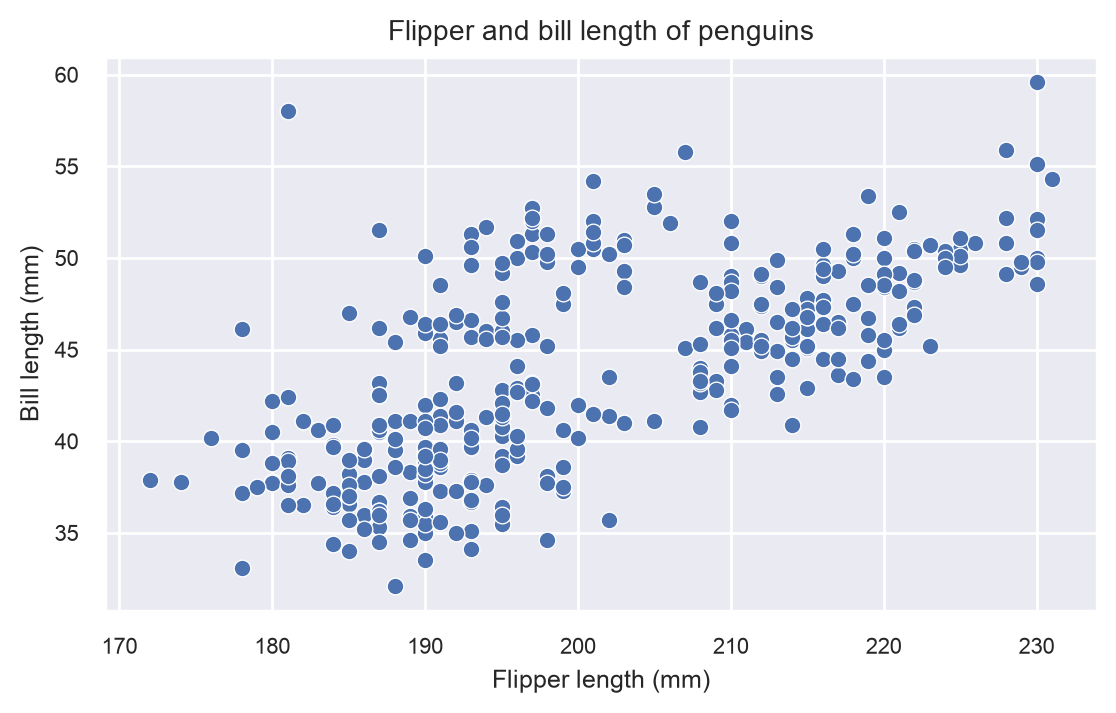

In [956]:
fig, ax = plt.subplots()
sns.scatterplot(data=df_penguins, x="flipper_length_mm", y="bill_length_mm", ax=ax)
ax.set(title="Flipper and bill length of penguins",
       xlabel="Flipper length (mm)", ylabel="Bill length (mm)");

*See also:* Adding a title and axis labels (C1) · Labelling a seaborn plot (C3) · Six principles of good plots (C4)

### Honest plots

#### Starting bar charts at zero

**C4.04**

`ax.set_ylim(0, …)`

***(non-examinable)***

A bar is read by its length, so a bar chart whose axis starts above zero makes small differences look large.

Watch out: in the first chart the axis starts at 3500 g, so the Gentoo bar looks many times as long as the Adelie bar, although the mean is less than half as large again:

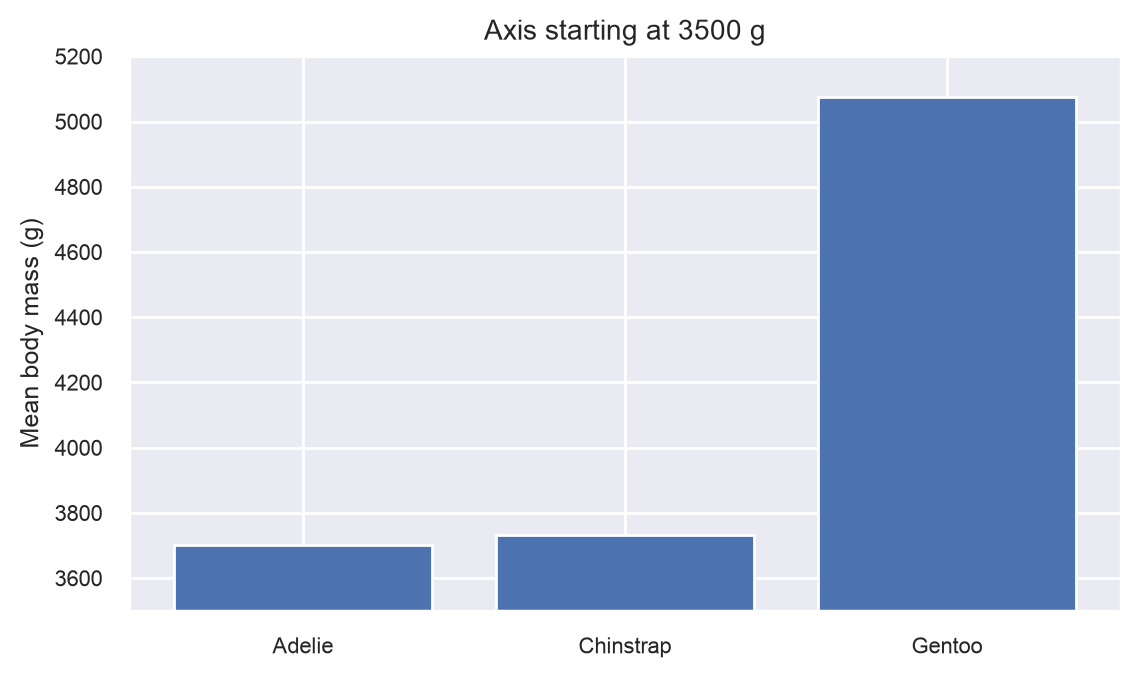

In [957]:
means = df_penguins.groupby("species")["body_mass_g"].mean()
fig, ax = plt.subplots()
ax.bar(means.index, means)
ax.set_ylim(3500, 5200)
ax.set(title="Axis starting at 3500 g", ylabel="Mean body mass (g)");

From zero, the lengths of the bars compare the means fairly:

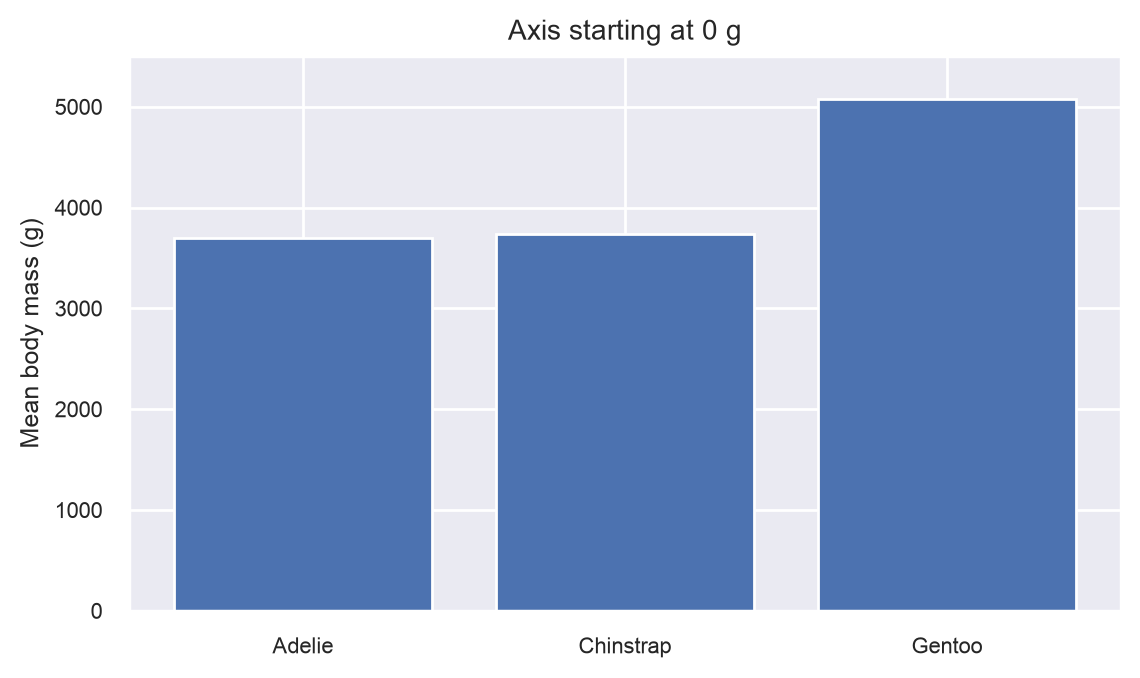

In [958]:
fig, ax = plt.subplots()
ax.bar(means.index, means)
ax.set_ylim(0, 5500)
ax.set(title="Axis starting at 0 g", ylabel="Mean body mass (g)");

Note: the rule is for bars. A scatter or line plot is read by position, so its axis may start near the data.

*See also:* Drawing a bar chart (C2) · Setting axis limits (C1) · Showing the data, not only the averages (C4)

#### Showing the data, not only the averages

**C4.05**

`sns.boxplot(...)   sns.stripplot(...)`

***(non-examinable)***

A bar for each mean hides how far the values spread and how much the groups overlap; a box plot with the points on top shows both, as well as the middle.

The bars give three means, and nothing about the penguins behind them:

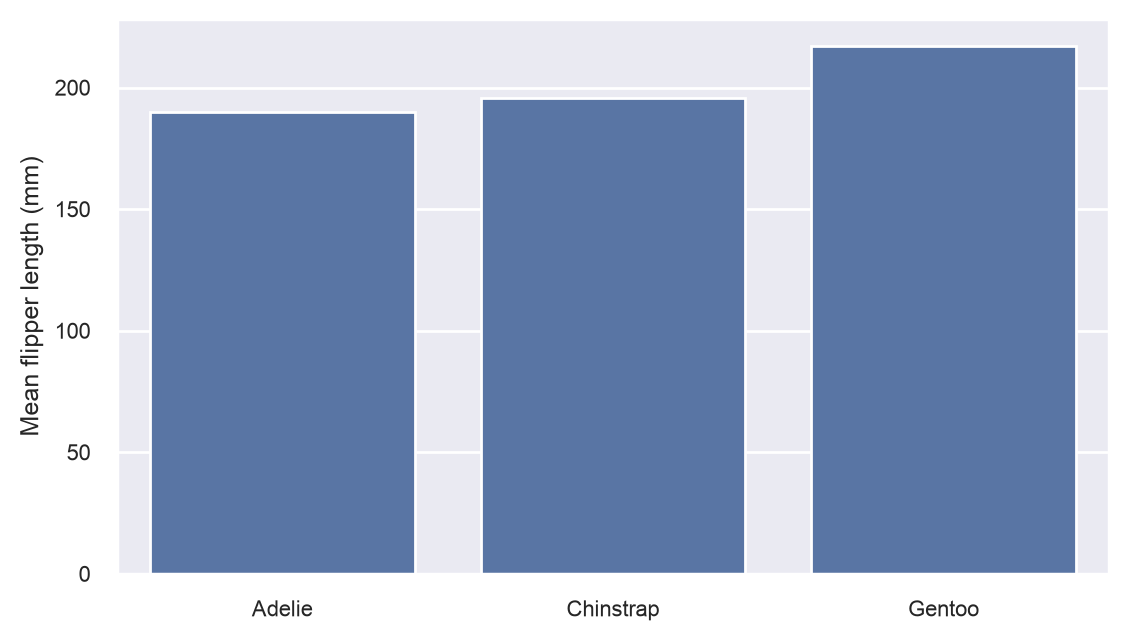

In [959]:
fig, ax = plt.subplots()
sns.barplot(data=df_penguins, x="species", y="flipper_length_mm", errorbar=None, ax=ax)
ax.set(xlabel="", ylabel="Mean flipper length (mm)");

With a box and the points, the spread and the overlap between Adelie and Chinstrap are visible:

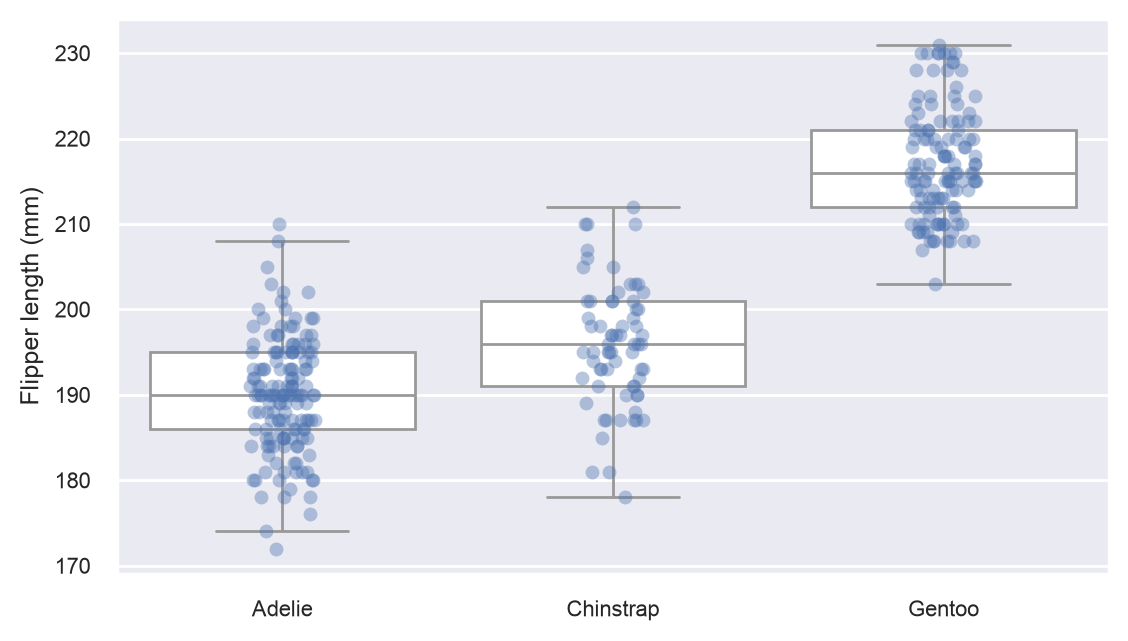

In [960]:
fig, ax = plt.subplots()
sns.boxplot(data=df_penguins, x="species", y="flipper_length_mm",
            color="white", showfliers=False, ax=ax)
sns.stripplot(data=df_penguins, x="species", y="flipper_length_mm", alpha=0.4, ax=ax)
ax.set(xlabel="", ylabel="Flipper length (mm)");

*See also:* Drawing a box plot with `boxplot` (C3) · Drawing a strip plot (C3) · Drawing a bar plot of values (C3) · Comparing groups with a box plot (D4)

### Clear plots

#### Colours that every reader can tell apart

**C4.06**

`palette="colorblind"   style="col"`

***(non-examinable)***

About one man in twelve cannot tell red from green, and a figure printed in grey loses colour altogether, so groups are shown with a colour-blind-friendly palette and a second cue such as marker shape.

The first plot tells the species apart by red and green alone:

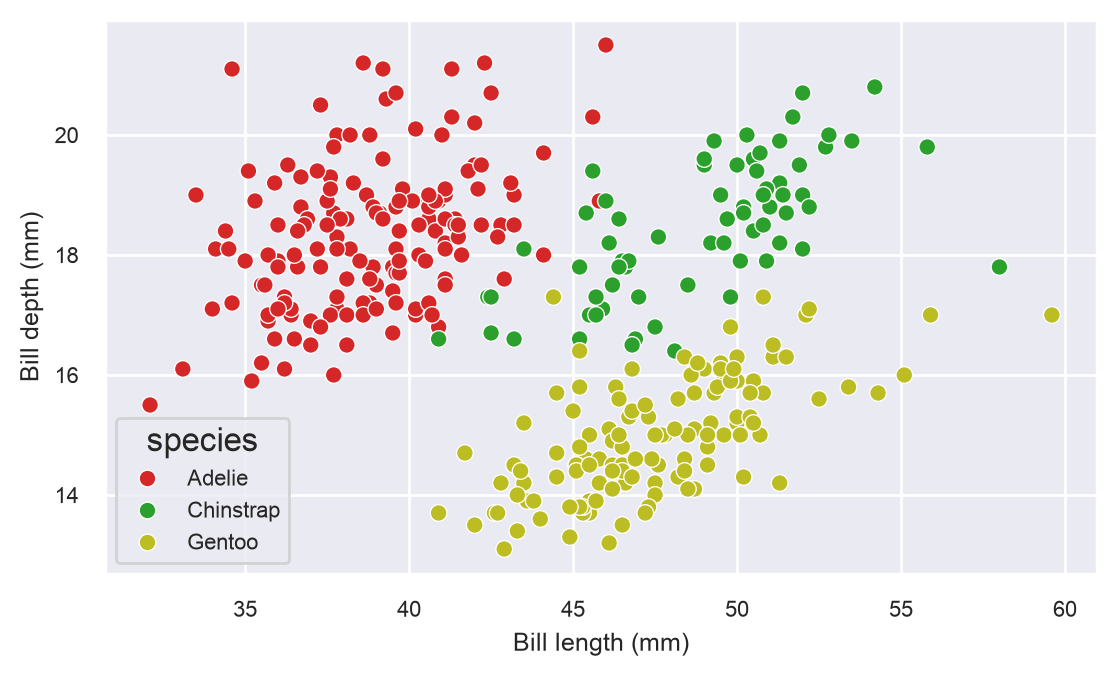

In [961]:
fig, ax = plt.subplots()
sns.scatterplot(data=df_penguins, x="bill_length_mm", y="bill_depth_mm", hue="species",
                palette=["tab:red", "tab:green", "tab:olive"], ax=ax)
ax.set(xlabel="Bill length (mm)", ylabel="Bill depth (mm)");

The second uses the `"colorblind"` palette and a different marker for each species:

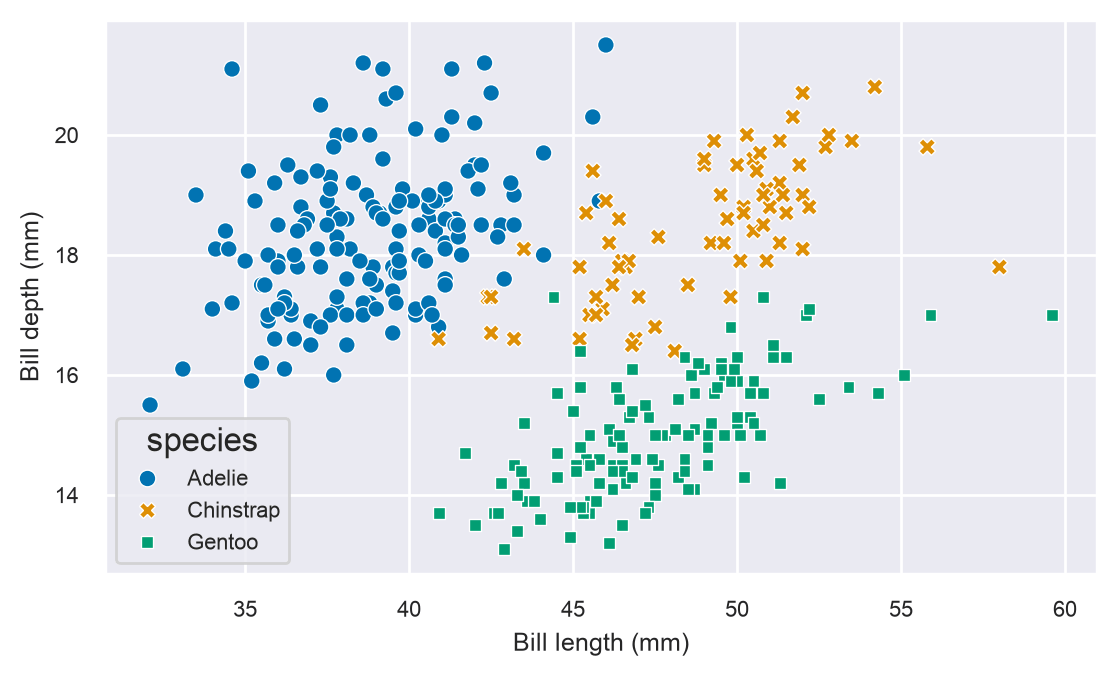

In [962]:
fig, ax = plt.subplots()
sns.scatterplot(data=df_penguins, x="bill_length_mm", y="bill_depth_mm", hue="species",
                style="species", palette="colorblind", ax=ax)
ax.set(xlabel="Bill length (mm)", ylabel="Bill depth (mm)");

*See also:* Choosing a colour palette (C3) · Colouring points by a value (C2) · Six principles of good plots (C4) · One message for each figure (C4)

#### One message for each figure

**C4.07**

***(non-examinable)***

Every extra colour, size and shape is one more thing the reader must decode; a figure that shows only what supports its message can be read at once, and a second message gets a second figure.

The first plot codes species, island and bill depth at once, and no message stands out:

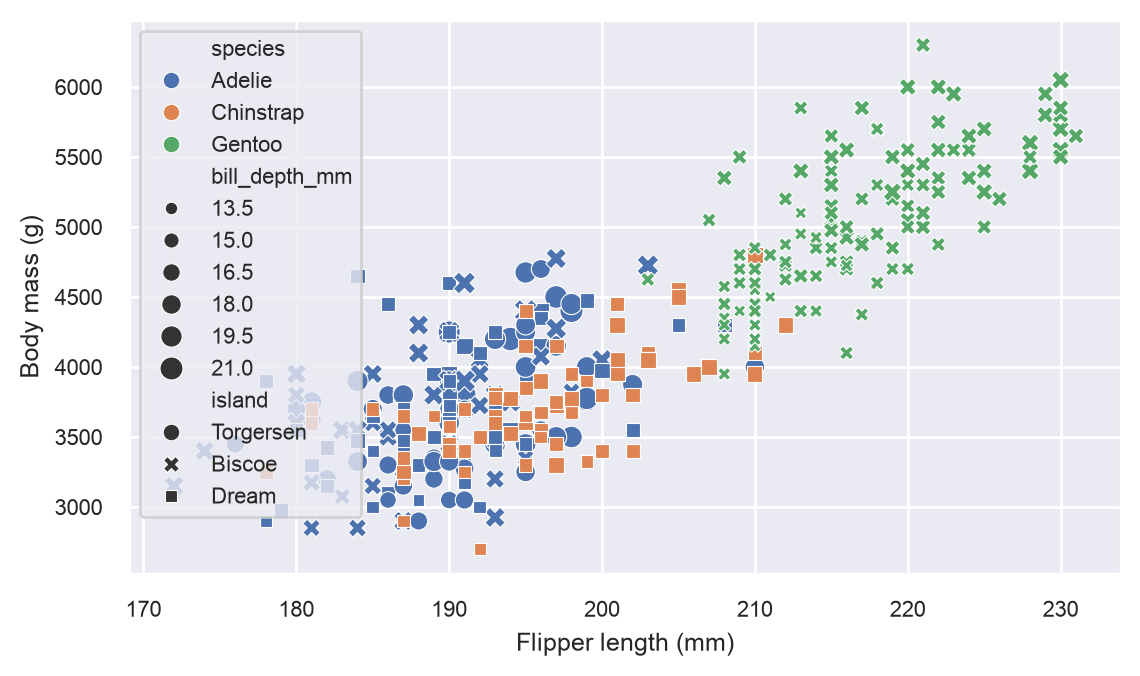

In [963]:
fig, ax = plt.subplots()
sns.scatterplot(data=df_penguins, x="flipper_length_mm", y="body_mass_g",
                hue="species", style="island", size="bill_depth_mm", ax=ax)
ax.set(xlabel="Flipper length (mm)", ylabel="Body mass (g)");

The second keeps only species, and the title states the message:

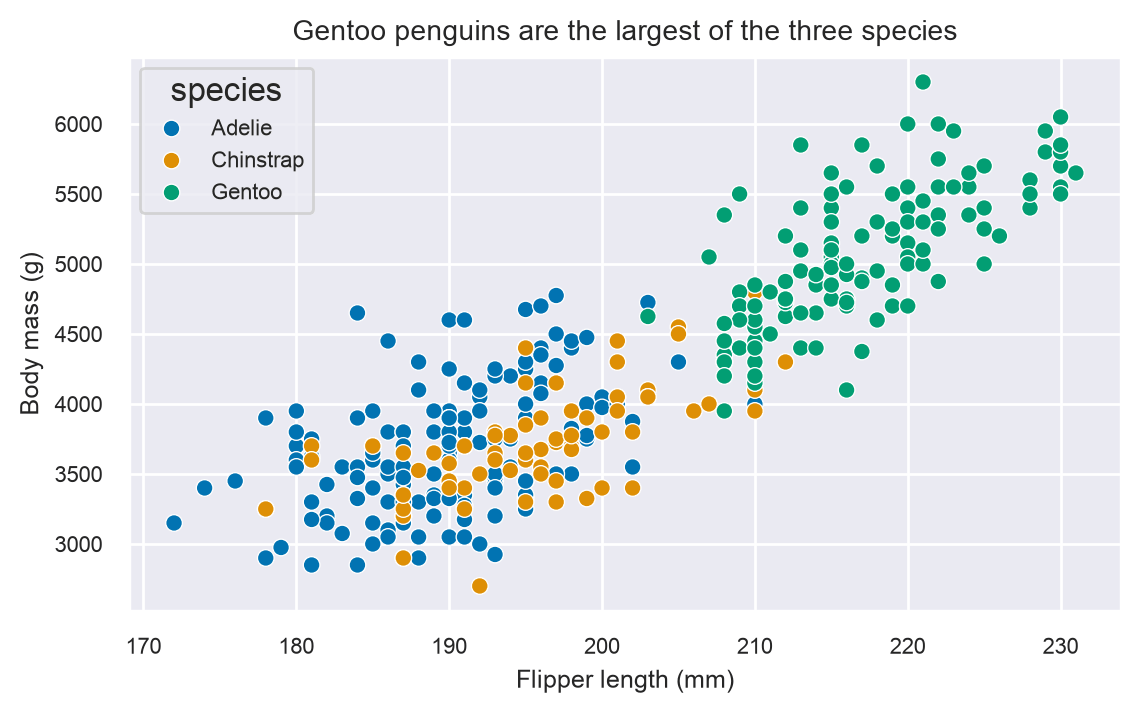

In [964]:
fig, ax = plt.subplots()
sns.scatterplot(data=df_penguins, x="flipper_length_mm", y="body_mass_g",
                hue="species", palette="colorblind", ax=ax)
ax.set(title="Gentoo penguins are the largest of the three species",
       xlabel="Flipper length (mm)", ylabel="Body mass (g)");

*See also:* Six principles of good plots (C4) · Drawing panels with `plt.subplots` (C2) · Colours that every reader can tell apart (C4)

### Before using a plot

#### Checking a plot before using it

**C4.08**

`ax.get_title()   ax.get_xlabel()   ax.get_ylim()`

***(non-examinable)***

A short check of every figure before it goes into a report or a presentation, with a function that reports the parts a reader needs.

Each "no" points to something to change:
1. Does the plot type fit the question (spread, groups, relationship, counts)?
2. Does each axis have a name and a unit, and the plot a title?
3. If it is a bar chart, does the axis start at zero?
4. Can the spread of the data be seen, not only the means?
5. Can the groups be told apart without colour?
6. Is there one message, and does the title or caption say it?

The function reports what can be checked from the code:

title:   MISSING
x label: MISSING
y label: MISSING
y axis starts at: 0.0


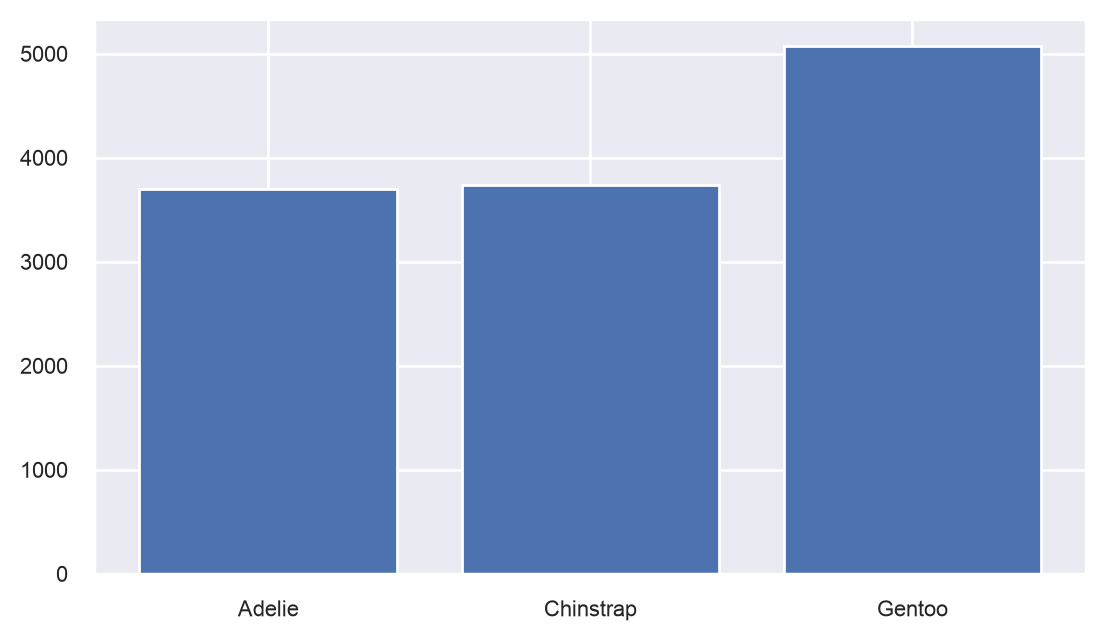

In [965]:
def check_plot(ax):
    """Print the parts of a plot that a reader needs."""
    print("title:  ", ax.get_title() or "MISSING")
    print("x label:", ax.get_xlabel() or "MISSING")
    print("y label:", ax.get_ylabel() or "MISSING")
    print("y axis starts at:", ax.get_ylim()[0])


means = df_penguins.groupby("species")["body_mass_g"].mean()
fig, ax = plt.subplots()
ax.bar(means.index, means)
check_plot(ax)

*See also:* Six principles of good plots (C4) · Labelling axes with names and units (C4) · Starting bar charts at zero (C4) · Checking an analysis before handing it in (D6)

# Part D – Probability and statistics